# Lab 9: Gyroscope model

**Goal.** Identify the TRIK gyroscope (yaw axis) so that `gyro_sim` behaves like the real sensor.

$$\omega_{meas} = Q_{\Delta}\big(\mathrm{sat}_{\pm\omega_{max}}[(1+s)\,\omega_{true} + b_0 + d\,t + n]\big), \quad n \sim \mathcal{N}(0,\sigma^2)$$

| Symbol | Meaning | Unit |
|---|---|---|
| $b_0$ | output when the robot is still | deg/s |
| $d$ | how fast $b_0$ changes | deg/s/min |
| $\omega_{max}$ | largest rate before the output clips | deg/s |
| $\Delta$ | smallest output step | deg/s |
| $\sigma$ | random spread around $b_0$ | deg/s |
| $s$ | how much the gyro over- or under-reports a turn | % |

**Experiment.** I chose Option A: open loop, the robot turns in place ($u_R = u$, $u_L = -u$). The program `lab9_gyro.qrs` runs in JavaScript with two threads: one logs, one drives.
1. **Warm-up**, 30 s: still, not logged.
2. **Static**, 3 min: still.
3. **Rotation**, 72 s: a sine, then a square wave, period 4 s, each at A = 30, 60 and 150 % of motor power for 12 s. At 150 % the power clips at ±100 %, so the gyro reaches its range and no hand spin is needed.
4. **Rest**: still. Only the first 3 s are used, because run 1 was touched later.

**Data.** One csv line every ~50 ms when still and ~90 ms when turning: `time()` [ms], `read()[3]` [256 µs ticks], raw gyro `readRawData()[2]`, `read()[2]` [mdeg/s], encoders E4 (left) and E3 (right) [deg]. `u` and `phase` are also logged but stay 0.
The gyro is analysed from the raw value. The reference heading comes from the wheels: $\theta_{enc} = \frac{r}{B}(\varphi_R - \varphi_L)$, with r = 0.043 m and B = 0.196 m.

In [1]:
from google.colab import files
uploaded = files.upload()

Saving lab9_gyro.csv to lab9_gyro.csv
Saving lab9_gyro_32.csv to lab9_gyro_32.csv


Libraries and robot parameters.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import cumulative_trapezoid
from scipy.signal import find_peaks

r = 0.043                                           # wheel radius, m
B = 0.196                                           # track width, m
phases = ['static', 'sin 30', 'sin 60', 'sin 150', 'rect 30', 'rect 60', 'rect 150', 'rest']   # phase names, A in %

**Loading.** Each log becomes a dictionary of arrays. The `phase` column in the log stays 0, so the phases are rebuilt from the schedule: still for the first 180 s, then six phases of 12 s counted from the moment a wheel first moves, then rest.

In [3]:
def load(file, name):
    data = np.genfromtxt(file, delimiter=',', skip_header=1)        # read the csv, text lines become nan
    data = data[~np.isnan(data).any(axis=1)]                        # drop the header line repeated inside the log
    t = (data[:, 0] - data[0, 0]) / 1000                            # time since the first line, s
    encL, encR = data[:, 4], data[:, 5]                             # wheel angles E4 (left) and E3 (right), deg

    moved = (np.diff(encL) != 0) | (np.diff(encR) != 0)             # a wheel moved since the previous line
    t1 = t[1:][moved & (t[1:] > 170)][0]                            # rotation start: first wheel motion after the still part
    keep = (t < 180) | ((t >= t1) & (t <= t1 + 75))                 # 3 min still, 72 s rotation + 3 s rest (run 1 was touched later)

    run = {'name': name}
    run['t'] = t[keep]                                              # time, s
    run['t_us'] = data[keep, 1]                                     # gyro timestamp, 256 us ticks
    run['raw'] = data[keep, 2]                                      # raw gyro, readRawData()[2]
    run['cal'] = data[keep, 3]                                      # read()[2], mdeg/s
    run['phase'] = np.where(run['t'] < 180, 0, np.minimum(1 + (run['t'] - t1) // 12, 7)).astype(int)   # 0 still, 1-6 rotation, 7 rest
    run['th_enc'] = r / B * (encR[keep] - encL[keep])               # heading from the wheels, deg
    return run

runs = [load('lab9_gyro.csv', 'run 1'), load('lab9_gyro_32.csv', 'run 2')]
for run in runs:
    dt = 1000 * np.diff(run['t'])                                   # time between lines, ms
    print(f"{run['name']}: {run['t'][-1]:.0f} s, one line every {np.median(dt[run['phase'][1:] == 0]):.0f} ms still, "
          f"{np.median(dt[run['phase'][1:] > 0]):.0f} ms turning")

run 1: 256 s, one line every 51 ms still, 89 ms turning
run 2: 255 s, one line every 54 ms still, 90 ms turning


## Raw → deg/s factor F
- `readRawData()[2]`: the sensor's untouched value, but an integer with no unit.
- `read()[2]`: in mdeg/s, but TRIK has already subtracted its own bias, by an amount we don't control.

I analyse the raw value and borrow only the unit:

read()[2] = (raw − TRIK's bias) × F

TRIK's bias only shifts the line up or down, so the slope of `read()[2]` against raw is F.
The two values are read a few ms apart, and when the rate changes fast they describe different moments and tilt the line. So I fit only steady moments: the still part, and unclipped turning samples that change by less than 2 % from their neighbours.

The plot shows all samples in grey and the steady ones used for the fit in colour.

run 1: F = 8.771 mdeg/s per raw unit
run 2: F = 8.777 mdeg/s per raw unit


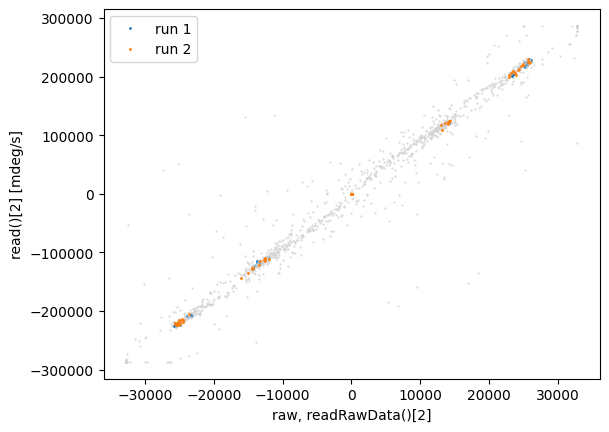

In [4]:
for run in runs:
    raw, cal = run['raw'], run['cal']
    change_prev = np.abs(np.diff(raw, prepend=np.nan))              # change from the previous sample
    change_next = np.abs(np.diff(raw, append=np.nan))               # change to the next sample
    turning = (np.abs(raw) >= 3000) & (np.abs(raw) <= 32000)        # clearly turning, not clipped
    steady_turn = turning & (change_prev < 0.02 * np.abs(raw)) & (change_next < 0.02 * np.abs(raw))
    steady = (run['phase'] == 0) | steady_turn                      # still part or steady turning

    run['F'] = np.polyfit(raw[steady], cal[steady], 1)[0] / 1000    # slope of the line, deg/s per raw unit
    run['w'] = raw * run['F']                                       # gyro rate, deg/s
    print(f"{run['name']}: F = {1000 * run['F']:.3f} mdeg/s per raw unit")
    plt.plot(raw, cal, '.', ms=1, color='lightgrey')                # all samples
    plt.plot(raw[steady], cal[steady], '.', ms=2, label=run['name'])  # samples used for the fit
plt.xlabel('raw, readRawData()[2]'); plt.ylabel('read()[2] [mdeg/s]'); plt.legend(); plt.show()

## 1. Offset $b_0$
$b_0$ is what the gyro outputs when the robot is still.
- **Value:** the mean of the first 30 s.
- **Left plot, $b_0(T)$:** the same mean over shorter times T. It shows how long the averaging needs to be.

**My calibration, `calibrate_gyro`:** average the first `T_CAL` seconds and track the max and min. If max − min > `MAX_RANGE`, the robot moved, so it returns `None` (try again). On the robot this needs no array, only a running mean, max and min.
- **`T_CAL` (right plot):** each T-second average is compared with the mean over the next minute, as heading error per minute. After `T_CAL` = 10 s the error drops by less than 10 %, because the bias itself wanders. Longer averaging only costs time.
- **`MAX_RANGE`:** the largest max − min in any still window of `T_CAL` seconds, plus 20 %.

run 1: b0 = 0.3154 ± 0.0029 deg/s
run 2: b0 = 0.2134 ± 0.0029 deg/s


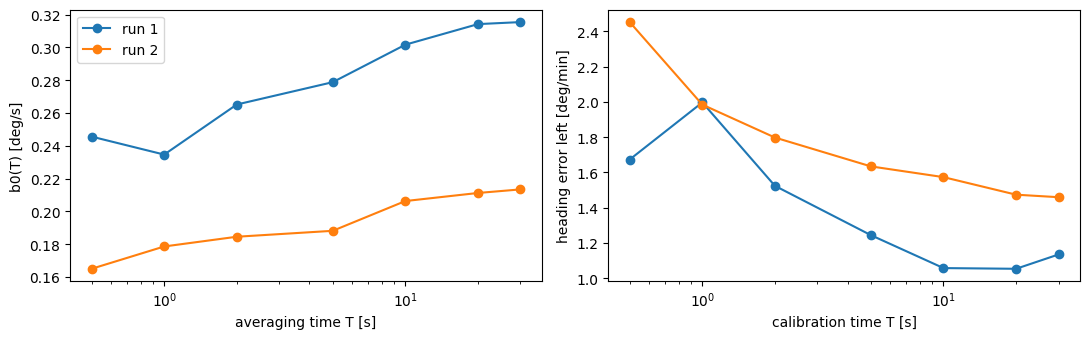

In [5]:
def error_left(t, w, T):
    """Heading error per minute after calibrating for T s and then driving for 1 min."""
    errors = []
    for a in np.arange(0, 120 - T, 5):                              # a calibration starting every 5 s
        b_cal = np.mean(w[(t >= a) & (t < a + T)])                  # what the calibration gives
        b_next = np.mean(w[(t >= a + T) & (t < a + T + 60)])        # the real bias during the next minute
        errors.append(b_cal - b_next)                               # bias error left, deg/s
    return 60 * np.sqrt(np.mean(np.square(errors)))                 # typical size (RMS), deg/min

T_list = [0.5, 1, 2, 5, 10, 20, 30]                                 # averaging / calibration times, s
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for run in runs:
    still = (run['phase'] == 0) & (np.diff(run['t_us'], prepend=np.nan) != 0)   # still part, each gyro sample once
    run['t_s'], run['w_s'], run['raw_s'] = run['t'][still], run['w'][still], run['raw'][still]
    t, w = run['t_s'], run['w_s']

    run['b0'] = np.mean(w[t < 30])                                  # b0 from the first 30 s
    se = np.std(w[t < 30]) / np.sqrt(np.sum(t < 30))                # its standard error
    print(f"{run['name']}: b0 = {run['b0']:.4f} ± {se:.4f} deg/s")
    run['err'] = [error_left(t, w, T) for T in T_list]
    ax[0].plot(T_list, [np.mean(w[t < T]) for T in T_list], 'o-', label=run['name'])   # b0(T)
    ax[1].plot(T_list, run['err'], 'o-', label=run['name'])         # heading error left
ax[0].set(xscale='log', xlabel='averaging time T [s]', ylabel='b0(T) [deg/s]'); ax[0].legend()
ax[1].set(xscale='log', xlabel='calibration time T [s]', ylabel='heading error left [deg/min]')
plt.tight_layout(); plt.show()

In [6]:
err_mean = (np.array(runs[0]['err']) + np.array(runs[1]['err'])) / 2   # both runs averaged
for T, e in zip(T_list, err_mean):                                  # shortest T within 10 % of the best
    if e < 1.1 * min(err_mean):
        T_CAL = T
        break

MAX_RANGE = 0                                                       # largest max - min while still
for run in runs:
    t, w = run['t_s'], run['w_s']
    for a in np.arange(0, 180 - T_CAL, T_CAL):                      # still windows of T_CAL seconds
        window = w[(t >= a) & (t < a + T_CAL)]
        MAX_RANGE = max(MAX_RANGE, np.max(window) - np.min(window))
MAX_RANGE = 1.2 * MAX_RANGE                                         # 20 % margin

def calibrate_gyro(t, w, T_cal=T_CAL, max_range=MAX_RANGE):
    w = w[t < t[0] + T_cal]                                         # first T_cal seconds
    if np.max(w) - np.min(w) > max_range:                           # the robot moved
        return None                                                 # try again
    return np.mean(w)                                               # b0

for run in runs:
    run['b_cal'] = calibrate_gyro(run['t_s'], run['w_s'])
    run['b_left'] = run['err'][T_list.index(T_CAL)] / 60            # bias error left, deg/s
    print(f"{run['name']}: calibrate_gyro = {run['b_cal']:.4f} deg/s, error left {60 * run['b_left']:.2f} deg/min")
moving = runs[0]['phase'] == 1                                      # robot turning (sin 30)
print(f"T_CAL = {T_CAL} s, MAX_RANGE = {MAX_RANGE:.2f} deg/s. On data with the robot turning: "
      f"{calibrate_gyro(runs[0]['t'][moving], runs[0]['w'][moving])}")

run 1: calibrate_gyro = 0.3016 deg/s, error left 1.06 deg/min
run 2: calibrate_gyro = 0.2063 deg/s, error left 1.57 deg/min
T_CAL = 10 s, MAX_RANGE = 0.56 deg/s. On data with the robot turning: None


## 2. Bias drift $d$
$d$ is how fast $b_0$ changes over time.
- **Value:** split the 3 min into six 30-s windows, take the mean of each, and fit a line through them. Its slope is $d$ (deg/s per min).
- **Plots:** the still rate integrated over time, which is the heading the gyro reports while the robot doesn't move.
  - **(a) Raw rate:** grows almost linearly, by about $b_0 \times 60$ deg per minute. This is the error if the bias is not removed.
  - **(b) Rate minus $b_0$:** what is left after removing the bias. Only drift and noise remain, a few degrees after 3 min.

run 1: d = -0.0108 deg/s/min; (a) 18.09 deg/min vs b0 * 60 = 18.92; (b) after 1, 2, 3 min: [-0.05 -0.93 -2.29] deg
run 2: d = +0.0199 deg/s/min; (a) 12.83 deg/min vs b0 * 60 = 12.80; (b) after 1, 2, 3 min: [-0.51 -1.25  1.02] deg


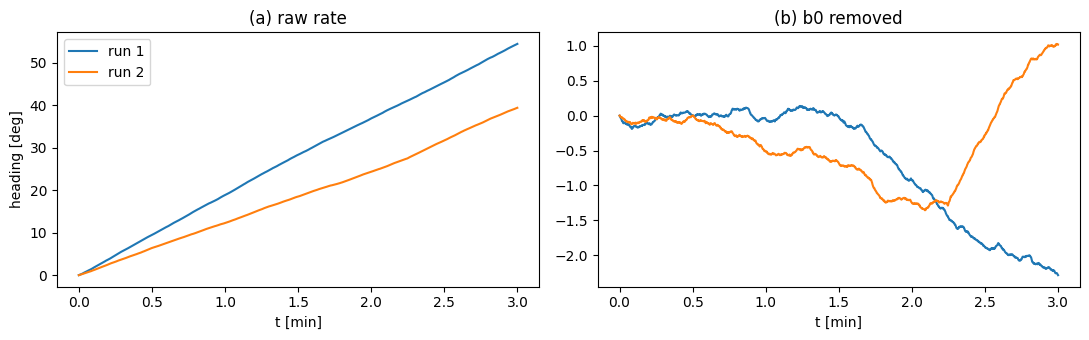

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for run in runs:
    t, w = run['t_s'], run['w_s']
    t_win, w_win = [], []
    for i in range(6):                                              # six 30-s windows
        inside = (t >= 30 * i) & (t < 30 * (i + 1))
        t_win.append(np.mean(t[inside]) / 60)                       # window centre, min
        w_win.append(np.mean(w[inside]))                            # window mean, deg/s
    run['d'] = np.polyfit(t_win, w_win, 1)[0]                       # slope, deg/s per min

    th_a = cumulative_trapezoid(w, t, initial=0)                    # (a) raw rate integrated, deg
    th_b = cumulative_trapezoid(w - run['b0'], t, initial=0)        # (b) rate minus b0 integrated, deg
    run['slope'] = np.polyfit(t / 60, th_a, 1)[0]                   # heading drift, deg/min
    print(f"{run['name']}: d = {run['d']:+.4f} deg/s/min; (a) {run['slope']:.2f} deg/min vs b0 * 60 = {60 * run['b0']:.2f}; "
          f"(b) after 1, 2, 3 min: {np.interp([60, 120, 180], t, th_b).round(2)} deg")
    ax[0].plot(t / 60, th_a, label=run['name'])
    ax[1].plot(t / 60, th_b, label=run['name'])
ax[0].set(title='(a) raw rate', xlabel='t [min]', ylabel='heading [deg]'); ax[0].legend()
ax[1].set(title='(b) b0 removed', xlabel='t [min]')
plt.tight_layout(); plt.show()

## Gyro against encoders
During the 72 s of rotation, two headings are compared:
- **$\theta_{enc}$** from the wheels, used as the true heading.
- **$\theta_{gyro}$**: the gyro rate minus my calibrated bias (`b_cal`), integrated over time. Its sign is set so that both agree on the positive direction (CCW).

**$e(t) = \theta_{gyro} - \theta_{enc}$** is the heading error left after my calibration. The top plots show both headings, and the bottom plots show $e(t)$ with the phases marked.

run 1: e before the first saturated turn (end of sin 60) 1 deg, left after the run (robot still) 53 deg
run 2: e before the first saturated turn (end of sin 60) 2 deg, left after the run (robot still) 29 deg


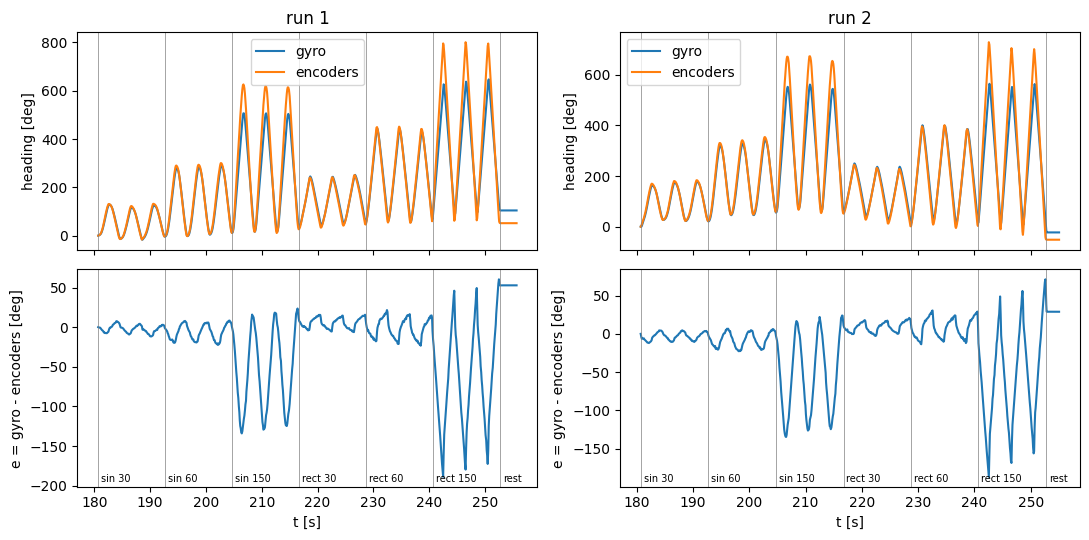

In [8]:
fig, ax = plt.subplots(2, 2, sharex='col', figsize=(11, 5.5))
for j, run in enumerate(runs):
    rot = run['phase'] >= 1                                         # rotation and rest
    t, w, ph = run['t'][rot], run['w'][rot], run['phase'][rot]
    th_enc = run['th_enc'][rot] - run['th_enc'][rot][0]             # encoder heading from 0, deg
    w_enc = np.gradient(th_enc, t)                                  # encoder rate, deg/s
    run['sign'] = np.sign(np.sum((w - run['b_cal']) * w_enc))       # +1: gyro positive when turning CCW
    th_gyro = run['sign'] * cumulative_trapezoid(w - run['b_cal'], t, initial=0)   # gyro heading, deg
    e = th_gyro - th_enc                                            # heading error, deg
    run.update(t_r=t, w_r=w, raw_r=run['raw'][rot], phase_r=ph, th_enc_r=th_enc, w_enc=w_enc, th_gyro=th_gyro)   # keep for the next sections

    ax[0, j].plot(t, th_gyro, label='gyro'); ax[0, j].plot(t, th_enc, label='encoders')
    ax[0, j].set(title=run['name'], ylabel='heading [deg]'); ax[0, j].legend()
    ax[1, j].plot(t, e); ax[1, j].set(xlabel='t [s]', ylabel='e = gyro - encoders [deg]')
    for p in range(1, 8):                                           # phase borders and names
        t0 = t[ph == p][0]
        ax[0, j].axvline(t0, c='grey', lw=0.5); ax[1, j].axvline(t0, c='grey', lw=0.5)
        ax[1, j].text(t0 + 0.5, 0.02, phases[p], transform=ax[1, j].get_xaxis_transform(), fontsize=7)
    print(f"{run['name']}: e before the first saturated turn (end of sin 60) {e[ph == 2][-1]:.0f} deg, "
          f"left after the run (robot still) {e[-1]:.0f} deg")
plt.tight_layout(); plt.show()

**Where $e(t)$ grows:**
- **Saturation (the main error):** at 150 % the wheels turn at over 400 deg/s, but the gyro stops at 287 deg/s, so $e$ drops by 135° (sine) to 190° (square) in each turn. Most of it comes back on the way back, but not all: $e$ is 1 to 2° before the first saturated turn and 29 to 53° after the run.
- **Scale factor:** at 30 and 60 %, $e$ moves by ~5 % of each turn (up to ~25°) and comes back when the robot turns back. The gyro reads ~5 % less in both directions, so a back-and-forth hides it. A one-way turn would add ~18° per full turn.
- **Bias:** after `calibrate_gyro` about 1 to 1.6 deg/min, so ~2° over these 72 s. It doesn't show in the plot.
- **Wheel slip:** $s$ is the same for the smooth sine and the abrupt square wave, so slip at reversals doesn't show on its own. It may still be hidden inside $s$: if the wheels slip or the real track width isn't exactly 0.196 m, the encoders are off, not the gyro.

## 3. Range $\omega_{max}$
$\omega_{max}$ is the fastest rate the gyro can report.
- **Value:** the largest and smallest raw values during the rotation × F.
- **Plot:** each dot is one sample, gyro rate against encoder rate. On the dashed diagonal both agree. At ±287 deg/s the dots turn flat: the encoders keep rising, but the gyro can't go higher. That flat part is saturation.

run 1: +287.4 / -287.1 deg/s, held for 104 samples
run 2: +287.6 / -287.3 deg/s, held for 106 samples


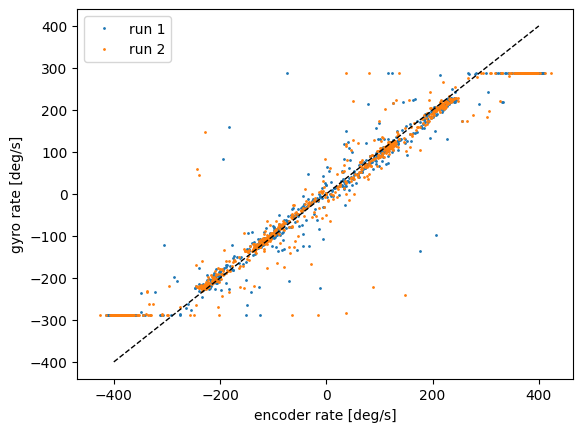

In [9]:
for run in runs:
    plt.plot(run['w_enc'], run['sign'] * (run['w_r'] - run['b_cal']), '.', ms=2, label=run['name'])
    top, bottom = np.max(run['raw_r']), np.min(run['raw_r'])        # largest and smallest raw values
    run['wmax'] = [top * run['F'], -bottom * run['F']]              # + and - limits, deg/s
    print(f"{run['name']}: +{run['wmax'][0]:.1f} / -{run['wmax'][1]:.1f} deg/s, held for {np.sum(run['raw_r'] == top)} samples")
plt.plot([-400, 400], [-400, 400], 'k--', lw=1)                     # gyro = encoders
plt.xlabel('encoder rate [deg/s]'); plt.ylabel('gyro rate [deg/s]'); plt.legend(); plt.show()

## 4. Resolution $\Delta$ and 5. Noise $\sigma$
Both come from the still part, with $b_0$ removed.
- **$\Delta$:** the smallest gap between two different raw values (1 raw unit) × F, the smallest change the gyro can show.
- **$\sigma$:** the standard deviation of the still rate, the size of the random noise.
- **Histogram:** bars one $\Delta$ wide, with a Gaussian curve of the same $\sigma$ on top. If the noise is Gaussian, about 0.27 % of samples fall beyond $3\sigma$; the printed numbers check this and the largest outlier.

$\sigma$ becomes R in Lab 12. It holds for this logging rate (~20 Hz).

run 1: Δ = 0.00877 deg/s; σ = 0.0699 deg/s at 20 Hz; beyond 3σ: 0.29 % (Gaussian 0.27 %), largest 3.6σ
run 2: Δ = 0.00878 deg/s; σ = 0.0738 deg/s at 19 Hz; beyond 3σ: 0.36 % (Gaussian 0.27 %), largest 3.8σ


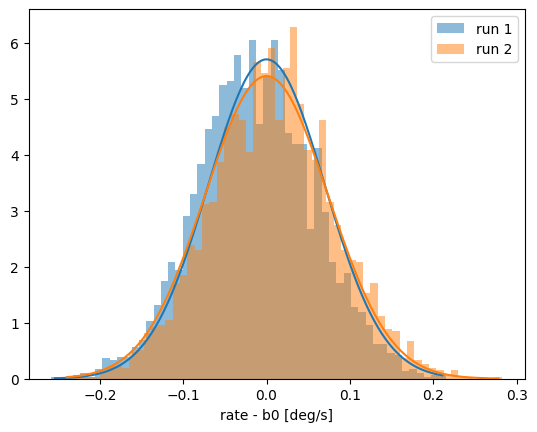

In [10]:
for run in runs:
    e = run['w_s'] - run['b0']                                      # still rate, b0 removed
    run['delta'] = delta = np.min(np.diff(np.unique(run['raw_s']))) * run['F']   # smallest raw step, deg/s
    run['sigma'] = sigma = np.std(e)                                # noise, deg/s
    run['fs'] = 1 / np.median(np.diff(run['t_s']))                  # sample rate, Hz
    print(f"{run['name']}: Δ = {delta:.5f} deg/s; σ = {sigma:.4f} deg/s at {run['fs']:.0f} Hz; "
          f"beyond 3σ: {100 * np.mean(np.abs(e) > 3 * sigma):.2f} % (Gaussian 0.27 %), largest {np.max(np.abs(e)) / sigma:.1f}σ")
    bars = plt.hist(e, bins=np.arange(e.min() - delta / 2, e.max() + delta, delta), density=True, alpha=0.5, label=run['name'])[2]
    x = np.linspace(e.min(), e.max(), 200)
    plt.plot(x, stats.norm.pdf(x, 0, sigma), color=bars[0].get_facecolor()[:3])   # Gaussian with the same σ
plt.xlabel('rate - b0 [deg/s]'); plt.legend(); plt.show()

## 6. Scale factor $s$
$s$ is how much the gyro over- or under-reports a turn.
- **Swings:** the robot turns back and forth. One swing goes from one turning point (where it stops and reverses) to the next. For each swing I compare the angle from the encoders, $\Delta\theta_{enc}$, with the angle from the gyro, $\Delta\theta_{gyro}$.
- **Fit:** each swing is one dot. A line through the origin, fitted separately to CCW and CW swings, has slope $1 + s$. On the dashed diagonal, $s = 0$.
- **Grey dots:** swings with clipped samples. They measure saturation, not $s$, so they are left out.
- **Table:** $s$ for each phase and direction, to check that it doesn't depend on speed or on the wave shape.

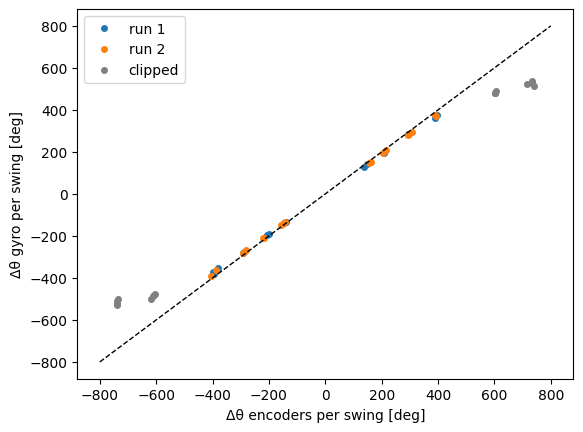

,phase,turn,run 1,run 2
0,sin 30,CCW,-5.3,-4.6
1,sin 30,CW,-4.2,-5.7
2,sin 60,CCW,-3.6,-3.9
3,sin 60,CW,-3.6,-4.6
4,rect 30,CCW,-5.4,-4.5
5,rect 30,CW,-5.3,-4.1
6,rect 60,CCW,-6.6,-4.9
7,rect 60,CW,-5.9,-5.3


In [11]:
swings = []                                                         # one row per swing
for run in runs:
    for p in range(1, 7):
        inside = run['phase_r'] == p
        t, th_enc, th_gyro, raw = run['t_r'][inside], run['th_enc_r'][inside], run['th_gyro'][inside], run['raw_r'][inside]
        gap = int(0.5 / np.median(np.diff(t)))                      # turning points at least 0.5 s apart
        peaks = find_peaks(th_enc, distance=gap)[0]                 # turning points at the top
        valleys = find_peaks(-th_enc, distance=gap)[0]              # turning points at the bottom
        turns = np.sort(np.concatenate([peaks, valleys]))
        for a, b in zip(turns[:-1], turns[1:]):                     # one swing from turn a to turn b
            d_enc = th_enc[b] - th_enc[a]                           # angle from the encoders, deg
            d_gyro = th_gyro[b] - th_gyro[a]                        # angle from the gyro, deg
            clipped = np.any(np.abs(raw[a:b]) >= 32700)             # gyro at its limit during the swing
            swings.append([run['name'], phases[p], 'CCW' if d_enc > 0 else 'CW', d_enc, d_gyro, clipped])
sw = pd.DataFrame(swings, columns=['run', 'phase', 'turn', 'd_enc', 'd_gyro', 'clipped'])

def fit_s(pick):
    """Line through the origin, least squares: slope = 1 + s. Returns s in %."""
    return 100 * (np.sum(sw.d_enc[pick] * sw.d_gyro[pick]) / np.sum(sw.d_enc[pick]**2) - 1)

for run in runs:
    ok = (sw.run == run['name']) & ~sw.clipped
    run['s'] = {turn: fit_s(ok & (sw.turn == turn)) / 100 for turn in ['CCW', 'CW']}
    plt.plot(sw.d_enc[ok], sw.d_gyro[ok], 'o', ms=4, label=run['name'])
plt.plot(sw.d_enc[sw.clipped], sw.d_gyro[sw.clipped], 'o', ms=4, color='grey', label='clipped')
plt.plot([-800, 800], [-800, 800], 'k--', lw=1)                     # gyro = encoders, s = 0
plt.xlabel('Δθ encoders per swing [deg]'); plt.ylabel('Δθ gyro per swing [deg]'); plt.legend(); plt.show()

table = []                                                          # s [%] per phase and direction
for p in ['sin 30', 'sin 60', 'rect 30', 'rect 60']:                # all swings at 150 % are clipped
    for turn in ['CCW', 'CW']:
        pick = ~sw.clipped & (sw.phase == p) & (sw.turn == turn)
        table.append([p, turn] + [round(fit_s(pick & (sw.run == run['name'])), 1) for run in runs])
pd.DataFrame(table, columns=['phase', 'turn', 'run 1', 'run 2'])

## Simulated gyro
`gyro_sim(omega_true, t)` applies the model formula step by step: scale, bias, drift, noise, clipping, rounding.
- **Parameters:** the average of both runs (`P`), saved to `gyro_params.json` for Labs 10 to 12.
- **Test:** I feed in the encoder rate of each run as the true rotation and lay the output over the real gyro. The plot shows the first 40 s, including the clipped sine at 150 %.
- **Number:** how far the simulated heading is from the real gyro's heading (RMS), compared with an ideal gyro that has no $s$ and no clipping. The smaller the number, the closer the model.

run 1, model: heading RMS vs the real gyro 15 deg
run 1, ideal gyro: heading RMS vs the real gyro 49 deg
run 2, model: heading RMS vs the real gyro 14 deg
run 2, ideal gyro: heading RMS vs the real gyro 46 deg


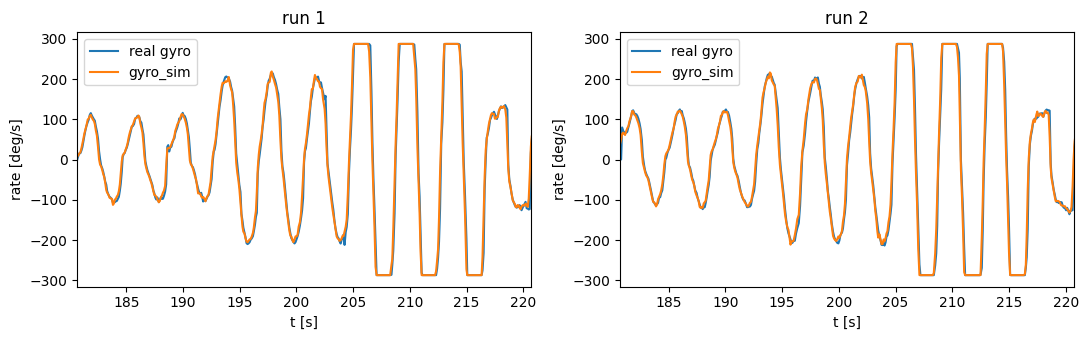

In [12]:
P = {}                                                              # model: both runs averaged
for key in ['b0', 'd', 'sigma', 'delta', 'F']:
    P[key] = (runs[0][key] + runs[1][key]) / 2
P['wmax'] = [(runs[0]['wmax'][i] + runs[1]['wmax'][i]) / 2 for i in range(2)]
P['s'] = {turn: (runs[0]['s'][turn] + runs[1]['s'][turn]) / 2 for turn in ['CCW', 'CW']}
with open('gyro_params.json', 'w') as f:
    json.dump(P, f, indent=1)                                       # for Labs 10-12

def gyro_sim(omega_true, t, p=P, seed=0):
    """Simulated TRIK gyro [deg/s]. omega_true [deg/s], CCW positive; t [s]."""
    s = np.where(omega_true >= 0, p['s']['CCW'], p['s']['CW'])      # scale-factor error per direction
    noise = np.random.default_rng(seed).normal(0, p['sigma'], len(t))
    w = (1 + s) * omega_true + p['b0'] + p['d'] / 60 * t + noise    # scale, bias, drift, noise
    w = np.clip(w, -p['wmax'][1], p['wmax'][0])                     # saturation
    return p['delta'] * np.round(w / p['delta'])                    # quantisation

ideal = {**P, 's': {'CCW': 0, 'CW': 0}, 'wmax': [np.inf, np.inf]}   # no s, no clipping
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for j, run in enumerate(runs):
    t, omega = run['t_r'], run['sign'] * run['w_enc']               # encoder rate as the true rotation
    for name, p in [('model', P), ('ideal gyro', ideal)]:
        th_sim = run['sign'] * cumulative_trapezoid(gyro_sim(omega, t, p) - P['b0'], t, initial=0)   # simulated heading
        print(f"{run['name']}, {name}: heading RMS vs the real gyro {np.sqrt(np.mean((th_sim - run['th_gyro'])**2)):.0f} deg")
    ax[j].plot(t, run['w_r'], label='real gyro'); ax[j].plot(t, gyro_sim(omega, t), label='gyro_sim')
    ax[j].set(title=run['name'], xlim=(t[0], t[0] + 40), xlabel='t [s]', ylabel='rate [deg/s]'); ax[j].legend()
plt.tight_layout(); plt.show()

## Parameter table

In [13]:
r1, r2 = runs
pd.DataFrame([
    ['Offset (bias)', 'b0', f"{r1['b0']:.4f}", f"{r2['b0']:.4f}", 'deg/s', 'static mean, T = 30 s'],
    ['Bias drift', 'd', f"{r1['d']:+.4f}", f"{r2['d']:+.4f}", 'deg/s/min', '30-s window means'],
    ['Heading drift, uncorrected', '', f"{r1['slope']:.1f}", f"{r2['slope']:.1f}", 'deg/min', 'slope of θ(t)'],
    ['Measurement range', '±ω_max', f"+{r1['wmax'][0]:.1f} / -{r1['wmax'][1]:.1f}", f"+{r2['wmax'][0]:.1f} / -{r2['wmax'][1]:.1f}", 'deg/s', 'saturation test'],
    ['Resolution', 'Δ', f"{r1['delta']:.5f}", f"{r2['delta']:.5f}", 'deg/s', 'quantisation step'],
    ['Noise std', 'σ', f"{r1['sigma']:.4f}", f"{r2['sigma']:.4f}", 'deg/s', 'static, 3 min'],
    ['Raw → deg/s factor', 'F', f"{r1['F']:.6f}", f"{r2['F']:.6f}", 'deg/s per raw', 'read() vs readRawData()'],
    ['Scale-factor error CCW / CW', 's', f"{100 * r1['s']['CCW']:+.1f} / {100 * r1['s']['CW']:+.1f}",
     f"{100 * r2['s']['CCW']:+.1f} / {100 * r2['s']['CW']:+.1f}", '%', 'gyro vs. encoder angle'],
    ['Positive rotation direction', '', 'CCW' if r1['sign'] > 0 else 'CW', 'CCW' if r2['sign'] > 0 else 'CW', '', 'gyro vs. encoder sign'],
], columns=['Parameter', 'Symbol', 'run 1', 'run 2', 'Unit', 'Method'])

,Parameter,Symbol,run 1,run 2,Unit,Method
0,Offset (bias),b0,0.3154,0.2134,deg/s,"static mean, T = 30 s"
1,Bias drift,d,-0.0108,+0.0199,deg/s/min,30-s window means
2,"Heading drift, uncorrected",,18.1,12.8,deg/min,slope of θ(t)
3,Measurement range,±ω_max,+287.4 / -287.1,+287.6 / -287.3,deg/s,saturation test
4,Resolution,Δ,0.00877,0.00878,deg/s,quantisation step
5,Noise std,σ,0.0699,0.0738,deg/s,"static, 3 min"
6,Raw → deg/s factor,F,0.008771,0.008777,deg/s per raw,read() vs readRawData()
7,Scale-factor error CCW / CW,s,-5.5 / -5.2,-4.5 / -5.0,%,gyro vs. encoder angle
8,Positive rotation direction,,CCW,CCW,,gyro vs. encoder sign


## For the analysis
Heading error [deg] from each source after 10 s, 1 min and 3 min. It shows which error dominates and when.
- **Bias, not removed:** $b_0 \cdot t$, grows linearly.
- **Bias left after `calibrate_gyro`:** the measured error left per minute × $t$, also linear but much smaller.
- **Drift:** the bias change $d$ added up over time, grows with $t^2$.
- **Noise:** $\sigma \sqrt{t / f_s}$, grows slowest, with $\sqrt{t}$ ($f_s$ = logging rate).
- **Scale factor:** $|s| \cdot 360°$, per full turn of the robot. It depends on how much the robot turns, not on time.

In [14]:
rows = {}                                                           # heading error [deg] per source
for run in runs:
    for T in [10, 60, 180]:                                         # 10 s, 1 min, 3 min
        rows[f"{run['name']}, {T} s"] = [
            abs(run['b0']) * T,                                     # bias, not removed
            run['b_left'] * T,                                      # bias left after calibrate_gyro
            abs(run['d']) / 60 * T**2 / 2,                          # drift
            run['sigma'] * np.sqrt(T / run['fs']),                  # noise
            max(abs(run['s']['CCW']), abs(run['s']['CW'])) * 360]   # scale factor, per full turn
pd.DataFrame(rows, index=['bias, not removed', 'bias left after calibrate_gyro', 'drift', 'noise',
                          'scale factor (per turn)']).round(2)

,"run 1, 10 s","run 1, 60 s","run 1, 180 s","run 2, 10 s","run 2, 60 s","run 2, 180 s"
"bias, not removed",3.15,18.92,56.77,2.13,12.80,38.41
bias left after calibrate_gyro,0.18,1.06,3.17,0.26,1.57,4.72
drift,0.01,0.32,2.91,0.02,0.60,5.38
noise,0.05,0.12,0.21,0.05,0.13,0.23
scale factor (per turn),19.81,19.81,19.81,17.98,17.98,17.98
